In [1]:
# Terry Chan # 1010156028
# Leon Yiliang Qian #
# PHY224H1F 2024 Circuits Exercise - Light bulb
# Oct 6, 2024

In [2]:
# Setting up the program
import numpy as np
import pandas as pd
from uncertainties import unumpy as unp
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit


In [3]:
# Reading the data from csv file
data = pd.read_csv('Light_bulb.csv')

# Removving the first row
data = data.drop(0)

# Extracting data
voltage = data['Voltage (V)']
current = data['Current (mA)']

# Converting to uncertainties
voltage = np.hstack((
    unp.uarray(voltage[0:2], .05/100 * voltage[1:3] + 5 * .0001),
    unp.uarray(voltage[2:], .05/100 * voltage[3] + 2 * .001)
))

current = unp.uarray(current, .2/100 * current + .005)

voltage, current

(array([1.986+/-0.0019912000000000003, 2.9824+/-0.0024895,
        3.979+/-0.0039895, 4.977+/-0.0039895, 5.974+/-0.0039895,
        6.972+/-0.0039895, 7.97+/-0.0039895, 8.968+/-0.0039895,
        9.964+/-0.0039895], dtype=object),
 array([9.369+/-0.023738000000000002, 11.705+/-0.02841, 13.704+/-0.032408,
        15.56+/-0.03612, 17.298+/-0.03959599999999999, 18.948+/-0.042896,
        20.539+/-0.046078, 22.859+/-0.050718, 24.551+/-0.054102],
       dtype=object))

In [4]:
# Defining the power podel 
def power_law(x, a, b):
    return a * x**b

# Defining the ideal model
def ideal_model(x, a):
    return a * x**.6

# Defining the linear model
def linear(x, a, b):
    return a * x + b

In [5]:
# Curve fitting with the power law
popt_pow, pcov_pow = curve_fit(power_law, unp.nominal_values(voltage), unp.nominal_values(current), sigma=unp.std_devs(current), absolute_sigma=True)
perr_pow = np.sqrt(np.diag(pcov_pow))
a_pow, b_pow = popt_pow
a_err_pow, b_err_pow = perr_pow

# Curve fitting with the ideal model
popt_ideal, pcov_ideal = curve_fit(ideal_model, unp.nominal_values(voltage), unp.nominal_values(current), sigma=unp.std_devs(current), absolute_sigma=True)
perr_ideal = np.sqrt(np.diag(pcov_ideal))
a_ideal = popt_ideal[0]
a_err_ideal = perr_ideal[0]

# Curve fitting with the linearized log model
log_voltage = unp.log10(voltage)
log_current = unp.log10(current)
popt_log, pcov_log = curve_fit(linear, unp.nominal_values(log_voltage), unp.nominal_values(log_current), sigma=unp.std_devs(log_current), absolute_sigma=True)
perr_log = np.sqrt(np.diag(pcov_log))
a_log, b_log = popt_log
a_err_log, b_err_log = perr_log

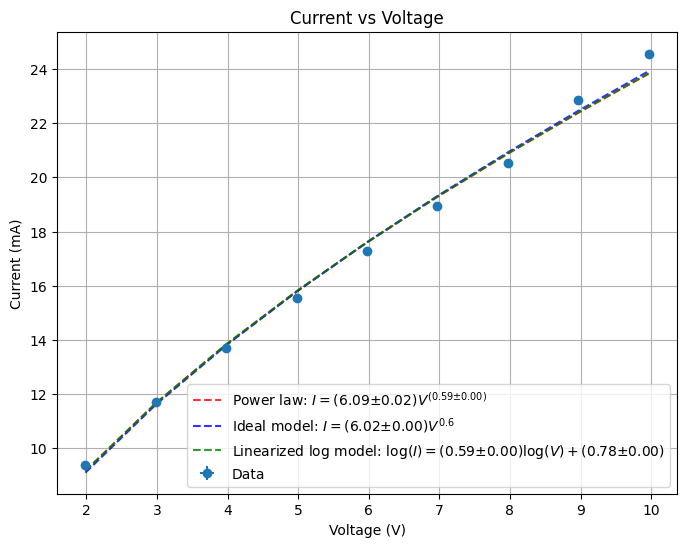

In [6]:
# Plotting the data and fits
fig, ax = plt.subplots(figsize=(8, 6))

ax.errorbar(unp.nominal_values(voltage), unp.nominal_values(current), xerr=unp.std_devs(voltage), yerr=unp.std_devs(current), fmt='o', label='Data')

ax.plot(unp.nominal_values(voltage), power_law(unp.nominal_values(voltage), a_pow, b_pow),
        label=f'Power law: $I = ({a_pow:.2f}±{a_err_pow:.2f})V^{{({b_pow:.2f}±{b_err_pow:.2f})}}$',
        alpha=.8,
        linestyle='--',
        color='r')

ax.plot(unp.nominal_values(voltage), ideal_model(unp.nominal_values(voltage), a_ideal),

        label=f'Ideal model: $I = ({a_ideal:.2f}±{a_err_ideal:.2f})V^{{0.6}}$',
        alpha=.8,
        linestyle='--',
        color='b')

ax.plot(unp.nominal_values(voltage), 10**linear(unp.nominal_values(log_voltage), a_log, b_log),
        label=f'Linearized log model: $\\log(I) = ({a_log:.2f}±{a_err_log:.2f}) \\log(V) + ({b_log:.2f}±{b_err_log:.2f})$',
        alpha=.8,
        linestyle='--',
        color='g')

ax.set_xlabel('Voltage (V)')
ax.set_ylabel('Current (mA)')
ax.set_title('Current vs Voltage')
ax.legend()
ax.grid()
plt.savefig('linear_axis.png')
plt.show()

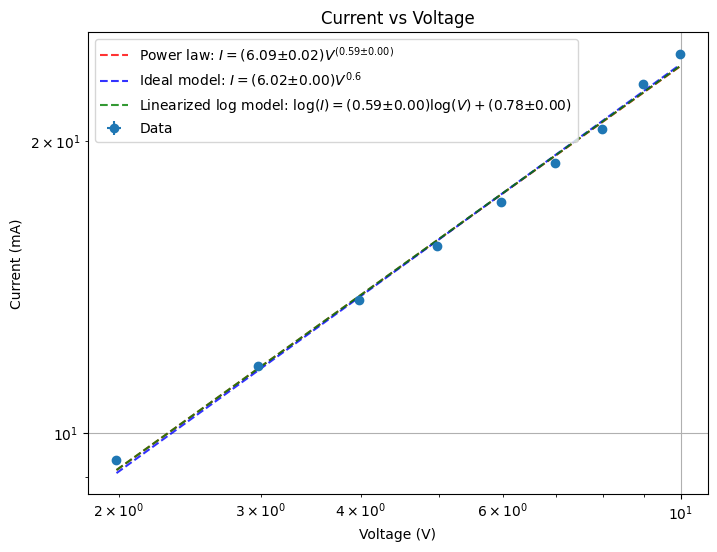

In [7]:
# Plotting the data and fits on log-log scale
fig, ax = plt.subplots(figsize=(8, 6))

ax.errorbar(unp.nominal_values(voltage), unp.nominal_values(current), xerr=unp.std_devs(voltage), yerr=unp.std_devs(current), fmt='o', label='Data')

ax.plot(unp.nominal_values(voltage), power_law(unp.nominal_values(voltage), a_pow, b_pow),
        label=f'Power law: $I = ({a_pow:.2f}±{a_err_pow:.2f})V^{{({b_pow:.2f}±{b_err_pow:.2f})}}$',
        alpha=.8,
        linestyle='--',
        color='r')

ax.plot(unp.nominal_values(voltage), ideal_model(unp.nominal_values(voltage), a_ideal),
        label=f'Ideal model: $I = ({a_ideal:.2f}±{a_err_ideal:.2f})V^{{0.6}}$',
        alpha=.8,
        linestyle='--',
        color='b')

ax.plot(unp.nominal_values(voltage), 10**linear(unp.nominal_values(log_voltage), a_log, b_log),
        label=f'Linearized log model: $\\log(I) = ({a_log:.2f}±{a_err_log:.2f}) \\log(V) + ({b_log:.2f}±{b_err_log:.2f})$',
        alpha=.8,
        linestyle='--',
        color='g')

ax.set_xlabel('Voltage (V)')
ax.set_ylabel('Current (mA)')
ax.set_title('Current vs Voltage')
ax.legend()
ax.grid()
ax.set_xscale('log')
ax.set_yscale('log')
plt.savefig('log_axis.png')
plt.show()

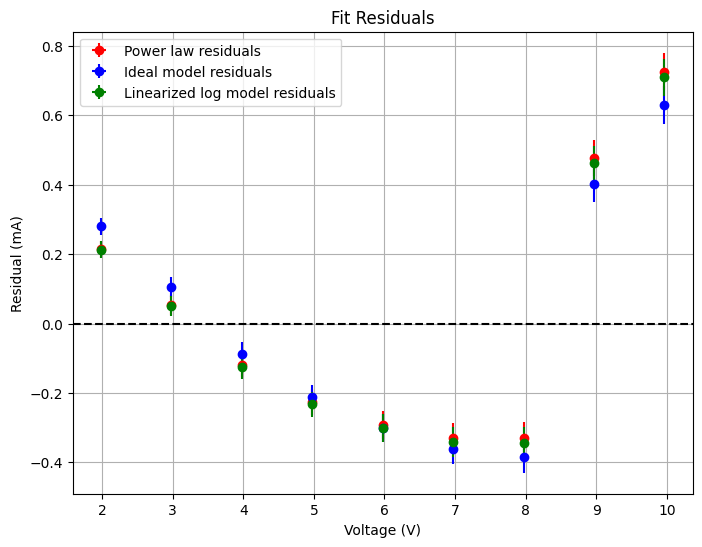

In [8]:
# Calculating the residuals
residuals_pow = current - power_law(voltage, a_pow, b_pow)
residuals_ideal = current - ideal_model(voltage, a_ideal)
residuals_log = 10**log_current - 10**linear(log_voltage, a_log, b_log)

# Plotting residuals
fig, ax = plt.subplots(figsize=(8, 6))
ax.errorbar(unp.nominal_values(voltage), unp.nominal_values(residuals_pow), xerr=unp.std_devs(voltage), yerr=unp.std_devs(residuals_pow), fmt='o', label='Power law residuals', color='r')
ax.errorbar(unp.nominal_values(voltage), unp.nominal_values(residuals_ideal), xerr=unp.std_devs(voltage), yerr=unp.std_devs(residuals_ideal), fmt='o', label='Ideal model residuals', color='b')
ax.errorbar(unp.nominal_values(voltage), unp.nominal_values(residuals_log), xerr=unp.std_devs(voltage), yerr=unp.std_devs(residuals_log), fmt='o', label='Linearized log model residuals', color='g')
ax.axhline(0, color='k', linestyle='--')
ax.set_xlabel('Voltage (V)')
ax.set_ylabel('Residual (mA)')
ax.set_title('Fit Residuals')
ax.legend()
ax.grid()
plt.savefig('residuals.png')
plt.show()

In [9]:
# Calculating chi-squared
chi2_pow = np.sum((residuals_pow / unp.std_devs(current))**2)
chi2_ideal = np.sum((residuals_ideal / unp.std_devs(current))**2)
chi2_log = np.sum((residuals_log / unp.std_devs(current))**2)

# Calculating degrees of freedom
dof_pow = len(voltage) - 2
dof_ideal = len(voltage) - 1
dof_log = len(voltage) - 2

# Calculating reduced chi-squared
chi2_red_pow = chi2_pow / dof_pow
chi2_red_ideal = chi2_ideal / dof_ideal
chi2_red_log = chi2_log / dof_log

# Printing results
print(f'Power law: I = ({a_pow:.4f}±{a_err_pow:.4f})V^({b_pow:.4f}±{b_err_pow:.4f})')
print(f'Ideal model: I = ({a_ideal:.4f}±{a_err_ideal:.4f})V^0.6')
print(f'Linearized log model: log(I) = ({a_log:.4f}±{a_err_log:.4f}) log(V) + ({b_log:.4f}±{b_err_log:.4f})')
print(f'Power law chi-squared: {chi2_pow:.4f}')
print(f'Ideal model chi-squared: {chi2_ideal:.4f}')
print(f'Linearized log model chi-squared: {chi2_log:.4f}')
print(f'Power law reduced chi-squared: {chi2_red_pow:.4f}')
print(f'Ideal model reduced chi-squared: {chi2_red_ideal:.4f}')
print(f'Linearized log model reduced chi-squared: {chi2_red_log:.4f}')

Power law: I = (6.0946±0.0173)V^(0.5930±0.0016)
Ideal model: I = (6.0219±0.0046)V^0.6
Linearized log model: log(I) = (0.5933±0.0016) log(V) + (0.7849±0.0012)
Power law chi-squared: 571.4806+/-48.3999
Ideal model chi-squared: 590.3280+/-49.2947
Linearized log model chi-squared: 571.9606+/-48.4305
Power law reduced chi-squared: 81.6401+/-6.9143
Ideal model reduced chi-squared: 73.7910+/-6.1618
Linearized log model reduced chi-squared: 81.7087+/-6.9186
